# 02 - Secant method: operating point of a diode circuit

**Goal.** Implement the secant method and compare it with bisection.

**Problem (my own).** A source $V_s = 5\,\text{V}$ drives a resistor $R = 1\,\text{k}\Omega$ in series with a diode. The diode current follows the Shockley equation, so the diode voltage is $V_d = n V_T \ln(1 + I/I_s)$ with $I_s = 10^{-12}$ A and $n V_T = 0.02585$ V. Kirchhoff's voltage law gives

$$f(I) = V_s - I R - n V_T \ln\!\left(1 + \frac{I}{I_s}\right) = 0.$$

In [1]:
import sys
sys.path.insert(0, "../src")  # lets this notebook run without installing the package

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6.5, 3.6), "axes.grid": True})
from scipy.optimize import newton

from nummeth import bisection, secant

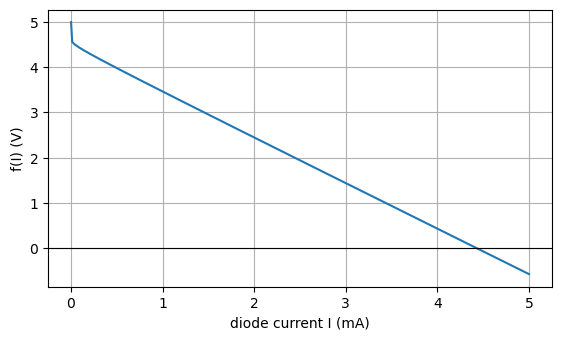

In [2]:
VS, R, IS, NVT = 5.0, 1000.0, 1e-12, 0.02585

def f(i):
    return VS - i * R - NVT * np.log1p(i / IS)

i = np.linspace(0, 5e-3, 400)
plt.plot(i * 1e3, f(i)); plt.axhline(0, color="k", lw=0.8)
plt.xlabel("diode current I (mA)"); plt.ylabel("f(I) (V)"); plt.show()

## Method

The secant method replaces the derivative in Newton's method with the slope of the line through the last two iterates:

$$x_{k+1} = x_k - f(x_k)\,\frac{x_k - x_{k-1}}{f(x_k) - f(x_{k-1})}.$$

It needs two starting values but no bracket and no derivative.

In [3]:
sec = secant(f, 1e-3, 3e-3, tol=1e-12)
print(f"current    = {sec.root * 1e3:.6f} mA")
print(f"iterations = {sec.iterations}, converged = {sec.converged}")
vd = NVT * np.log1p(sec.root / IS)
print(f"diode voltage = {vd:.4f} V, resistor drop = {sec.root * R:.4f} V, sum = {vd + sec.root * R:.6f} V (should be {VS})")

current    = 4.425853 mA
iterations = 4, converged = True
diode voltage = 0.5741 V, resistor drop = 4.4259 V, sum = 5.000000 V (should be 5.0)


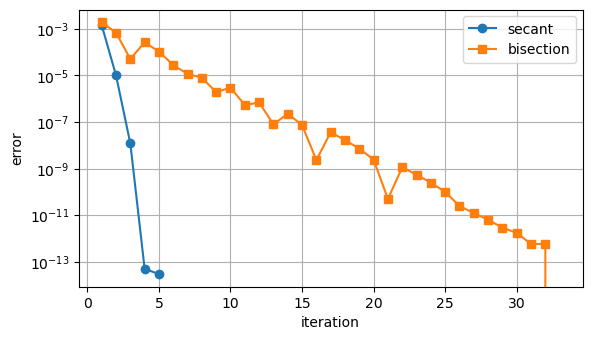

secant: 4 iterations | bisection: 33 iterations (same tolerance)


In [4]:
bis = bisection(f, 1e-6, 5e-3, tol=1e-12)
ref = bis.root
sec_err = [abs(x - ref) for x in sec.history[1:]]
bis_err = [abs(x - ref) for x in bis.history]

plt.semilogy(range(1, len(sec_err) + 1), sec_err, "o-", label="secant")
plt.semilogy(range(1, len(bis_err) + 1), bis_err, "s-", label="bisection")
plt.xlabel("iteration"); plt.ylabel("error"); plt.legend(); plt.show()
print(f"secant: {sec.iterations} iterations | bisection: {bis.iterations} iterations (same tolerance)")

In [5]:
# SciPy's newton() uses the secant method when no derivative is supplied.
ref_root = newton(f, 1e-3, x1=3e-3, tol=1e-12, full_output=True)
print(f"scipy newton (secant): {ref_root[0] * 1e3:.6f} mA, iterations = {ref_root[1].iterations}")
print(f"difference from mine : {abs(ref_root[0] - sec.root):.2e} A")

scipy newton (secant): 4.425853 mA, iterations = 4
difference from mine : 0.00e+00 A


In [6]:
# Experiment: how do different starting pairs behave?
for x0, x1 in [(1e-3, 3e-3), (1e-9, 2e-9), (0.1, 0.2), (4e-3, 4.0001e-3)]:
    try:
        r = secant(f, x0, x1, tol=1e-12)
        print(f"start ({x0:.1e}, {x1:.1e}) -> {r.root * 1e3:.6f} mA in {r.iterations} iterations, converged = {r.converged}")
    except ZeroDivisionError as err:
        print(f"start ({x0:.1e}, {x1:.1e}) -> ZeroDivisionError: {err}")

start (1.0e-03, 3.0e-03) -> 4.425853 mA in 4 iterations, converged = True
start (1.0e-09, 2.0e-09) -> 4.425853 mA in 8 iterations, converged = True
start (1.0e-01, 2.0e-01) -> 4.425853 mA in 5 iterations, converged = True
start (4.0e-03, 4.0e-03) -> 4.425853 mA in 4 iterations, converged = True


## Observations

- How many iterations did secant need compared with bisection, and why?
- Which of the starting pairs above was the slowest, and what does that tell you?
- Try to find a starting pair that makes the secant method fail. What goes wrong?

Secant needed 4 iterations and bisection needed 33 for the same tolerance, mainly because of their different rates of convergence. Bisection only uses the sign of f and cuts the interval in half at each step, so it converges linearly. The secant method intelligently projects a secant line through the last two points and uses its x-intercept as the next guess, which converges superlinearly (order about 1.618).

The slowest starting pair was (1e-9, 2e-9), which took 8 iterations against 4 or 5 for the others. Near I = 0 the diode curve is extremely steep (it is a logarithm), so a straight line through those two points is a poor model of f and the first steps are inaccurate. Starts close to the root need fewer iterations, so the first guesses matter for secant.

The secant method fails when f(x_{k-1}) = f(x_k), because the denominator of the secant formula becomes zero. For this strictly decreasing f that only happens when the two starting values are equal (for example x0 = x1), because the secant line is then flat. The pair printed as (4.0e-03, 4.0e-03) did not fail: the two values are close but not equal (4e-3 and 4.0001e-3), and the printing rounds them.